# Setup

In [1]:
import re
import requests
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas import DataFrame
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
import statsmodels.api as sm
from nltk.corpus import stopwords
from gensim import corpora
import gensim
from empath import Empath
import json
import os
from math import ceil
from pathlib import Path
import mpltern
import torch
from dotenv import load_dotenv
from nltk.corpus import sentiwordnet as swn
from nltk.stem import WordNetLemmatizer
from nltk.wsd import lesk
from transformers import AutoModel, AutoTokenizer


C:\code\nlp_project\.venv_arm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
nltk.download('brown')
nltk.download('wordnet_ic')
nltk.download('gutenberg')
nltk.download('punkt_tab')
nltk.download("stopwords")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("wordnet")
nltk.download("sentiwordnet")


[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package wordnet_ic to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet_ic is already up-to-date!
[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nl

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package sentiwordnet to
[nltk_data]     C:\Users\rasmus\AppData\Roaming\nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!


True

# Shared functions

In [14]:
characters = {
    "Elizabeth": ["Elizabeth", "Lizzy", "Eliza"],
    "Darcy": ["Darcy"],
    "Jane": ["Jane"],
    "Bingley": ["Bingley"],
    "Wickham": ["Wickham"],
    "Lydia": ["Lydia"],
    "Mrs. Bennet": ["Mrs. Bennet"],
    "Mr. Bennet": ["Mr. Bennet"],
    "Collins": ["Collins"],
    "Charlotte": ["Charlotte"],
    "Lady Catherine": ["Lady Catherine"],
    "Kitty": ["Kitty"],
    "Mary": ["Mary"],
}


def getBookText():
    url = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"
    response = requests.get(url)
    return response.text


def getSpeech():
    text = getBookText().replace("\r\n", "\n")
    paragraphs = text.split("\n\n")

    speech = {name: [] for name in characters}
    for p in paragraphs:
        p = " ".join(p.split())
        quotes = re.findall(r'[“"](.*?)[”"]', p)
        if not quotes:
            continue
        narration = re.sub(r'[“"].*?[”"]', " ", p)
        for name, aliases in characters.items():
            pattern = r"\b(" + "|".join(aliases) + r")\b"
            if re.search(pattern, narration):
                speech[name].extend(quotes)
                break
    return speech


def getSpeechAsTokens():
    tokenDict = dict()
    speech = getSpeech()
    for person, quotes in speech.items():
        quotesString = ' '.join(quotes)
        quotesString = quotesString.lower()
        tokens = nltk.word_tokenize(quotesString)
        tokenDict[person] = tokens
    return tokenDict


def getBookTokens():
    text = getBookText()
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    return tokens


def printMatrix(matrix, rowLabels=None, columnLabels=None, decimalCount=2, labels=True):
    dataFrame = DataFrame(
        matrix,
        columns=columnLabels,
        index=rowLabels
    )
    print(dataFrame.round(decimalCount).to_string(header=labels, index=labels))


def printMatrixTransposed(matrix, rowLabels=None, columnLabels=None, decimalCount=2, labels=True):
    dataFrame = DataFrame(
        matrix,
        columns=columnLabels,
        index=rowLabels
    )
    print(dataFrame.T.round(decimalCount).to_string(header=labels, index=labels))


def filterTokenListTask5And6(tokenList):
    generalStopWords = stopwords.words('english')
    manualStopWords = ['must', 'one', 'shall', 'could', 'would', 'may', 'think', 'must', 'us', 'much',
                       'well', 'know', 'never', 'see', 'good', 'oh', 'ever', 'always', 'make', 'sure', 'dear', 'indeed', 'better',
                       'man', 'nothing', 'like', 'young', 'miss', 'give', 'say', 'hope', 'really', 'certainly',
                       'way', 'manner', 'go', 'little', 'let', 'time', 'ask', 'great', 'last', 'upon', 'often', 'quite', 'soon', 'come', 'tell']

    filteredTokens = []
    for token in tokenList:
        # Tokens have to be alphanumeric
        if not token.isalnum():
            continue
        # Tokens cannot be stopwords
        if token in generalStopWords:
            continue
        if token in manualStopWords:
            continue
        filteredTokens.append(token)

    return filteredTokens


def filterTokenListTask7(tokenList):
    generalStopWords = stopwords.words('english')
    manualStopWords = ['must', 'one', 'shall', 'could', 'would', 'may', 'think', 'must',
                       'us', 'much', 'well', 'know', 'never', 'see', 'good', 'oh', 'ever', 'always', 'make', 'sure', 'dear', 'indeed']

    filteredTokens = []
    for token in tokenList:
        # Tokens have to be alphanumeric
        if not token.isalnum():
            continue
        # Tokens cannot be stopwords
        if token in generalStopWords:
            continue
        if token in manualStopWords:
            continue
        filteredTokens.append(token)

    return filteredTokens


def getSpeechAsFilteredTokens(filterTokenList):
    speechAsTokens = getSpeechAsTokens()

    speechAsFilteredTokens = dict()
    for person, tokens in speechAsTokens.items():
        speechAsFilteredTokens[person] = filterTokenList(tokens)

    return speechAsFilteredTokens


dataframes = {}
for name, quotes in getSpeech().items():
    if quotes:
        dataframes[name] = pd.DataFrame({"text": quotes})


# Task 1: Character Importance

In [5]:
def task1():
    text = " ".join(getBookText().split())
    sentences = nltk.sent_tokenize(text)

    results = []
    for name, aliases in characters.items():
        pattern = r"\b(" + "|".join(aliases) + r")\b"
        frequency = len(re.findall(pattern, text))
        citations = sum(1 for s in sentences if re.search(pattern, s))
        results.append((name, frequency, citations))

    results.sort(key=lambda r: r[1], reverse=True)

    print(f"{'Rank':<6}{'Character':<16}{'Frequency':<11}{'Citations'}")
    for i, (name, frequency, citations) in enumerate(results, 1):
        print(f"{i:<6}{name:<16}{frequency:<11}{citations}")

task1()


Rank  Character       Frequency  Citations
1     Elizabeth       765        748
2     Darcy           429        416
3     Bingley         309        304
4     Jane            303        289
5     Wickham         200        192
6     Collins         189        181
7     Lydia           175        167
8     Mrs. Bennet     159        153
9     Lady Catherine  122        121
10    Mr. Bennet      92         89
11    Charlotte       87         85
12    Kitty           72         69
13    Mary            43         43


# Task 2: Character Speech and Lexical Statistics

In [6]:
def task2():
    speech = getSpeech()

    # One dataframe per character + statistics
    rows = []
    for name, quotes in speech.items():
        df = pd.DataFrame({"text": quotes})
        tokens = nltk.word_tokenize(" ".join(df["text"]))
        words = [w.lower() for w in tokens if w.isalpha()]
        vocabulary = set(words)
        tags = [tag for word, tag in nltk.pos_tag(tokens)]

        rows.append({
            "Character": name,
            "Vocabulary size": len(vocabulary),
            "Tokens": len(tokens),
            "Adjectives": sum(t.startswith("JJ") for t in tags),
            "Adverbs": sum(t.startswith("RB") for t in tags),
            "Verbs": sum(t.startswith("VB") for t in tags),
            "Nouns": sum(t.startswith("NN") for t in tags),
            "Vocabulary (sample)": sorted(vocabulary)[:5],
        })

    summary = pd.DataFrame(rows).sort_values("Tokens", ascending=False)
    print(summary.to_string(index=False))

task2()


     Character  Vocabulary size  Tokens  Adjectives  Adverbs  Verbs  Nouns                              Vocabulary (sample)
     Elizabeth             1110    5428         360      323    915    867         [a, able, abominable, abominably, about]
          Jane              511    1793         122      130    333    246   [a, above, accepted, accomplishments, account]
         Darcy              524    1622         102      117    281    255          [a, abhorrence, abilities, able, about]
   Mrs. Bennet              368    1230          80       92    205    186                  [a, able, about, above, advise]
       Bingley              345     988          61       73    172    168 [a, abominable, accomplished, adept, admiration]
         Lydia              253     777          31       61    145    133                   [a, about, afraid, again, all]
     Charlotte              244     612          39       48    102    108        [a, able, advance, affection, afterwards]
    Mr. 

# Task 3: Vocabulary Growth and Heaps' Law

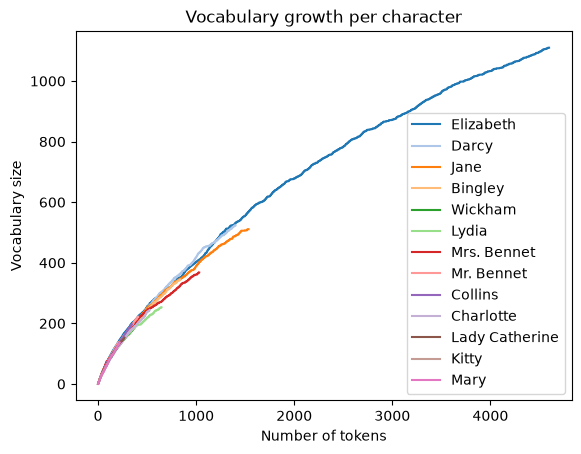

     Character  Tokens  Vocabulary    K  beta     R2  Adj. R2
     Elizabeth    4598        1110 2.97 0.711 0.9947   0.9947
          Jane    1534         511 2.35 0.743 0.9939   0.9939
         Darcy    1402         524 1.84 0.787 0.9970   0.9970
   Mrs. Bennet    1031         368 2.22 0.749 0.9836   0.9836
       Bingley     837         345 1.81 0.788 0.9960   0.9960
         Lydia     647         253 2.13 0.755 0.9839   0.9838
     Charlotte     526         244 1.58 0.812 0.9967   0.9967
       Wickham     409         203 1.66 0.807 0.9939   0.9939
    Mr. Bennet     408         222 1.34 0.860 0.9962   0.9962
       Collins     345         197 1.50 0.839 0.9967   0.9967
Lady Catherine     269         153 1.41 0.849 0.9973   0.9972
          Mary     221         137 1.02 0.914 0.9977   0.9977
         Kitty     101          70 1.29 0.871 0.9958   0.9957


In [7]:
def task3():
    speech = getSpeech()
    plt.gca().set_prop_cycle(color=plt.cm.tab20.colors)

    rows = []
    for name, quotes in speech.items():
        df = pd.DataFrame({"text": quotes})
        tokens = nltk.word_tokenize(" ".join(df["text"]))
        words = [w.lower() for w in tokens if w.isalpha()]

        # vocabulary size after each token
        N, V, seen = [], [], set()
        for i, w in enumerate(words, 1):
            seen.add(w)
            N.append(i)
            V.append(len(seen))
        plt.plot(N, V, label=name)

        # Heaps' law
        x, y = np.log(N), np.log(V)
        beta, logK = np.polyfit(x, y, 1)
        y_pred = logK + beta * x
        r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)
        n = len(x)
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 2)

        rows.append({
            "Character": name,
            "Tokens": len(words),
            "Vocabulary": len(seen),
            "K": round(np.exp(logK), 2),
            "beta": round(beta, 3),
            "R2": round(r2, 4),
            "Adj. R2": round(adj_r2, 4),
        })

    plt.xlabel("Number of tokens")
    plt.ylabel("Vocabulary size")
    plt.title("Vocabulary growth per character")
    plt.legend()
    plt.show()

    summary = pd.DataFrame(rows).sort_values("Tokens", ascending=False)
    print(summary.to_string(index=False))

task3()


# Task 4: Modal verb graphs

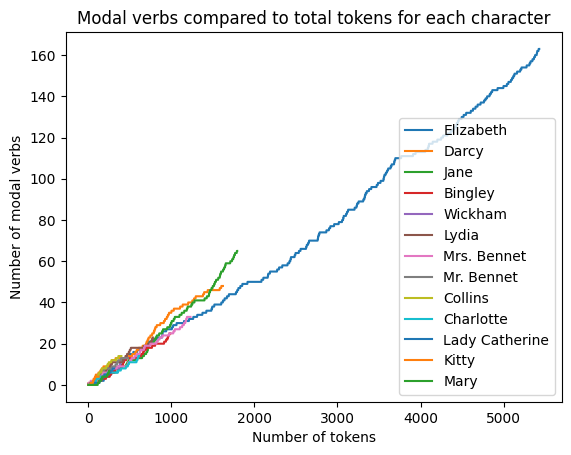

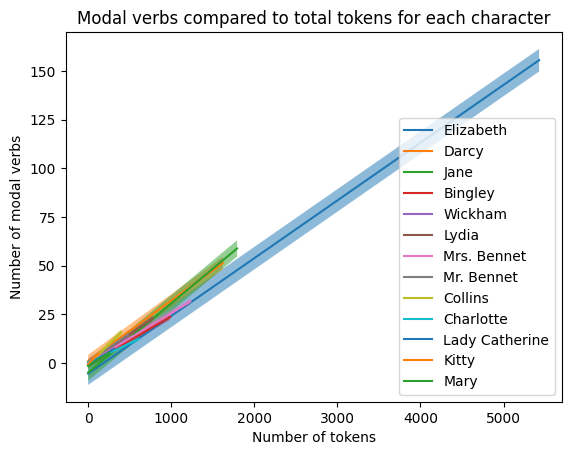

In [13]:
def task4(displayRaw=False):
    modalVerbs = ("can", "may", "must", "shall", "will",
                  "could", "might", "should", "would")

    speechAsTokens = getSpeechAsTokens()

    for person, tokens in speechAsTokens.items():
        xEntries = []
        yEntries = []
        tokenCount = 0
        modalVerbCount = 0

        for token in tokens:
            tokenCount += 1
            if token in modalVerbs:
                modalVerbCount += 1
            xEntries.append(tokenCount)
            yEntries.append(modalVerbCount)

        # Calculate fitted values
        a, b = np.polyfit(xEntries, yEntries, 1)
        yEntriesFitted = []
        for xEntry in xEntries:
            yFitted = a * xEntry + b
            yEntriesFitted.append(yFitted)

        if displayRaw:
            # Draw raw data
            plt.plot(xEntries, yEntries, label=person)
        else:
            # Draw fitted line
            plt.plot(xEntries, yEntriesFitted, label=person)
            # Draw confidence interval
            xEntries = np.array(xEntries)
            yEntries = np.array(yEntries)
            xEntriesConst = sm.add_constant(xEntries)
            model = sm.OLS(yEntries, xEntriesConst).fit()
            xPredictions = np.linspace(xEntries.min(), xEntries.max())
            xPredictionsConst = sm.add_constant(xPredictions)
            pred = model.get_prediction(
                xPredictionsConst).summary_frame(alpha=0.10)
            plt.fill_between(
                xPredictions,
                pred["obs_ci_lower"],
                pred["obs_ci_upper"],
                alpha=0.5,
            )

    plt.xlabel("Number of tokens")
    plt.ylabel("Number of modal verbs")
    plt.title("Modal verbs compared to total tokens for each character")
    plt.legend()
    plt.show()

task4(displayRaw=True)
task4(displayRaw=False)


# Task 5: Character similarity with frequent tokens

In [9]:
def task5():
    tokens = getBookTokens()
    filteredTokens = filterTokenListTask5And6(tokens)

    counter = Counter(filteredTokens)
    mostCommon = counter.most_common(5)
    tokenArray, countArray = zip(*mostCommon)
    print("Most frequent tokens in the whole textbook:")
    printMatrix([tokenArray, countArray], labels=False)
    print()

    mostCommonVector = []
    for token, count in mostCommon:
        mostCommonVector.append(token)

    vectorDict = dict()
    speechAsTokens = getSpeechAsTokens()
    for person, tokens in speechAsTokens.items():
        vectorDict[person] = [0, 0, 0, 0, 0]
        for token in tokens:
            for i, mostCommonToken in enumerate(mostCommonVector):
                if token == mostCommonToken:
                    vectorDict[person][i] += 1

    frequencyMatrix = list(vectorDict.values())

    print("Frequency of the five most frequent tokens for each character:")
    printMatrix(frequencyMatrix,
                rowLabels=vectorDict.keys(), columnLabels=mostCommonVector)
    print()

    cosineSimilarityMatrix = cosine_similarity(
        frequencyMatrix, frequencyMatrix)

    print("Cosine similarity between characters")
    printMatrix(cosineSimilarityMatrix, rowLabels=vectorDict.keys(),
                columnLabels=vectorDict.keys())

task5()


Most frequent tokens in the whole textbook:
elizabeth darcy said bennet bingley
      644   430  406    339     310



Frequency of the five most frequent tokens for each character:
                elizabeth  darcy  said  bennet  bingley
Elizabeth               1     17     6       1       12
Darcy                   0      2     0       0        1
Jane                    0      7     0       0        4
Bingley                 2     10     2       7        0
Wickham                 0      0     0       0        0
Lydia                   0      0     0       0        0
Mrs. Bennet             0      3     0       2        7
Mr. Bennet              0      0     0       0        0
Collins                 0      0     1       0        0
Charlotte               0      2     0       1        1
Lady Catherine          0      3     0       0        0
Kitty                   0      0     0       0        0
Mary                    0      0     0       0        0

Cosine similarity between characters
                Elizabeth  Darcy  Jane  Bingley  Wickham  Lydia  Mrs. Bennet  Mr. Bennet  Collins  Charlotte  Lady 

# Task 6: Character similarity with LDA

In [10]:
def task6():
    speechAsFilteredTokens = getSpeechAsFilteredTokens(filterTokenListTask5And6)
    people = speechAsFilteredTokens.keys()
    filteredTokenLists = list(speechAsFilteredTokens.values())

    dictionary = corpora.Dictionary(filteredTokenLists)
    corpus = [dictionary.doc2bow(text) for text in filteredTokenLists]

    topicCount = 5
    keywordCount = 10

    ldamodel = gensim.models.ldamodel.LdaModel(
        corpus, id2word=dictionary, num_topics=topicCount)
    topicStrings = ldamodel.print_topics(num_words=keywordCount)

    print("Topics:")
    for topic in topicStrings:
        print(topic)
    print()

    topics = ldamodel.show_topics(
        num_topics=ldamodel.num_topics,
        num_words=keywordCount,
        formatted=False
    )

    personTopicSimilarities = dict()
    for person in people:
        counter = Counter(speechAsFilteredTokens[person])

        personTopicSimilarities[person] = [0, 0, 0, 0, 0]
        for topicId, words in topics:
            for word, probability in words:
                if word in speechAsFilteredTokens[person]:
                    weight = probability * counter[word]
                    personTopicSimilarities[person][topicId] += weight

    print("Each person's similarity with each topic:")
    printMatrixTransposed(personTopicSimilarities)
    print()

    personTopicSimilarityMatrix = list(personTopicSimilarities.values())
    cosineSimilarityMatrix = cosine_similarity(
        personTopicSimilarityMatrix, personTopicSimilarityMatrix)

    print("Topic similarity between characters using cosine similarity")
    printMatrix(cosineSimilarityMatrix, columnLabels=people, rowLabels=people)

task6()


Topics:
(0, '0.005*"darcy" + 0.005*"lizzy" + 0.004*"bingley" + 0.003*"sister" + 0.003*"believe" + 0.003*"married" + 0.003*"forster" + 0.003*"wickham" + 0.002*"find" + 0.002*"love"')
(1, '0.009*"darcy" + 0.004*"believe" + 0.004*"lizzy" + 0.004*"bingley" + 0.003*"love" + 0.003*"world" + 0.003*"enough" + 0.003*"pride" + 0.003*"family" + 0.003*"wish"')
(2, '0.008*"darcy" + 0.005*"bingley" + 0.004*"believe" + 0.003*"anything" + 0.003*"feelings" + 0.003*"world" + 0.003*"perhaps" + 0.003*"since" + 0.003*"wish" + 0.003*"jane"')
(3, '0.007*"darcy" + 0.004*"sister" + 0.004*"believe" + 0.004*"bingley" + 0.003*"jane" + 0.003*"many" + 0.003*"anything" + 0.003*"lizzy" + 0.003*"wish" + 0.003*"something"')
(4, '0.009*"darcy" + 0.005*"bingley" + 0.004*"love" + 0.004*"lizzy" + 0.003*"every" + 0.003*"since" + 0.003*"something" + 0.003*"jane" + 0.003*"sister" + 0.003*"day"')

Each person's similarity with each topic:
                   0     1     2     3     4
Elizabeth       0.22  0.35  0.31  0.26  0.35

# Task 7: LLM topic similarity

In [11]:
# requires gemini api key in .env, check .env.example
def task7():
    speechAsFilteredTokens = getSpeechAsFilteredTokens(filterTokenListTask7)
    people = speechAsFilteredTokens.keys()
    filteredTokenLists = list(speechAsFilteredTokens.values())

    topicCount = 5
    keywordCount = 10
    load_dotenv()
    model = os.getenv("GEMINI_MODEL", "gemini-3.5-flash")
    # Prompt generated with help of ChatGPT
    prompt = (
        f"Find {topicCount} shared topics in these dialogue collections. "
        f"For each topic choose {keywordCount} keywords from the supplied tokens. "
        "Assign positive keyword weights summing to one within each topic. "
        'Return JSON as {"topics": [[0, [["word", 0.1], ...]], ...]}. '
        "Use topic IDs 0 to 4.\n" + json.dumps(filteredTokenLists)
    )
    # https://ai.google.dev/api/generate-content#method:-models.generatecontent
    response = requests.post(
        f"https://generativelanguage.googleapis.com/v1beta/models/{model}:generateContent",
        headers={"x-goog-api-key": os.environ["GEMINI_API_KEY"]},
        json={
            "contents": [{"parts": [{"text": prompt}]}],
            "generationConfig": {"temperature": 0, "responseMimeType": "application/json"},
        },
        timeout=180,
    )
    text = response.json()["candidates"][0]["content"]["parts"][-1]["text"]
    topics = json.loads(text)["topics"]
    print("Topics:")
    for topic in topics:
        print(topic)
    print()

    personTopicSimilarities = dict()
    for person in people:
        counter = Counter(speechAsFilteredTokens[person])

        personTopicSimilarities[person] = [0, 0, 0, 0, 0]
        for topicId, words in topics:
            for word, probability in words:
                if word in speechAsFilteredTokens[person]:
                    weight = probability * counter[word]
                    personTopicSimilarities[person][topicId] += weight

    print("Each person's similarity with each topic:")
    printMatrix(personTopicSimilarities)
    print()

    personTopicSimilarityMatrix = list(personTopicSimilarities.values())
    cosineSimilarityMatrix = cosine_similarity(
        personTopicSimilarityMatrix, personTopicSimilarityMatrix)

    print("Topic similarity between characters using cosine similarity")
    printMatrix(cosineSimilarityMatrix, columnLabels=people, rowLabels=people)

task7()


Topics:
[0, [['collins', 0.1], ['catherine', 0.1], ['offer', 0.1], ['refuse', 0.1], ['marry', 0.1], ['marriage', 0.1], ['daughter', 0.1], ['husband', 0.1], ['estate', 0.1], ['lady', 0.1]]]
[1, [['dance', 0.1], ['dancing', 0.1], ['music', 0.1], ['ball', 0.1], ['perform', 0.1], ['room', 0.1], ['sing', 0.1], ['partner', 0.1], ['handsome', 0.1], ['play', 0.1]]]
[2, [['darcy', 0.1], ['bingley', 0.1], ['sister', 0.1], ['jane', 0.1], ['elizabeth', 0.1], ['netherfield', 0.1], ['pemberley', 0.1], ['letter', 0.1], ['friend', 0.1], ['country', 0.1]]]
[3, [['wickham', 0.1], ['lydia', 0.1], ['meryton', 0.1], ['colonel', 0.1], ['forster', 0.1], ['officers', 0.1], ['captain', 0.1], ['town', 0.1], ['aunt', 0.1], ['london', 0.1]]]
[4, [['pride', 0.1], ['vanity', 0.1], ['character', 0.1], ['opinion', 0.1], ['proud', 0.1], ['mind', 0.1], ['feeling', 0.1], ['feelings', 0.1], ['human', 0.1], ['nature', 0.1]]]

Each person's similarity with each topic:
   Elizabeth  Darcy  Jane  Bingley  Wickham  Lydia  Mrs

# Task 8: BERT similarity

In [12]:
def getBertVector(text, tokenizer, model):
    inputs = tokenizer(text, truncation=True, return_overflowing_tokens=True)
    total = torch.zeros(model.config.hidden_size)
    count = 0

    for ids in inputs["input_ids"]:
        input_ids = torch.tensor([ids])
        with torch.no_grad():
            result = model(input_ids=input_ids)
            token_vectors = result.last_hidden_state
            token_vectors = token_vectors[0]
            output = token_vectors[1:-1]
        total += output.sum(dim=0)
        count += len(output)

    return (total / count).numpy()


def task8(dataframes):
    tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    model = AutoModel.from_pretrained("bert-base-uncased")

    vectors = []
    for _name, df in dataframes.items():
        vector = getBertVector(" ".join(df["text"]), tokenizer, model)
        vectors.append(vector)

    names = list(dataframes)
    embeddings = pd.DataFrame(vectors, index=names)
    similarity = pd.DataFrame(cosine_similarity(vectors), index=names, columns=names)
    print(f"BERT similarity:\n{similarity.round(3).to_string()}")
    return embeddings, similarity

task8(dataframes)



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights:  16%|█▌        | 32/199 [00:00<00:00, 277.95it/s]


Loading weights:  30%|███       | 60/199 [00:00<00:00, 266.02it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 859.27it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT similarity:
                Elizabeth  Darcy   Jane  Bingley  Wickham  Lydia  Mrs. Bennet  Mr. Bennet  Collins  Charlotte  Lady Catherine  Kitty   Mary
Elizabeth           1.000  0.991  0.993    0.980    0.968  0.945        0.980       0.969    0.968      0.983           0.961  0.899  0.949
Darcy               0.991  1.000  0.984    0.976    0.969  0.930        0.967       0.963    0.964      0.977           0.956  0.881  0.959
Jane                0.993  0.984  1.000    0.976    0.964  0.943        0.977       0.963    0.961      0.982           0.959  0.894  0.941
Bingley             0.980  0.976  0.976    1.000    0.935  0.948        0.975       0.972    0.963      0.963           0.967  0.890  0.927
Wickham             0.968  0.969  0.964    0.935    1.000  0.905        0.943       0.918    0.920      0.957           0.930  0.869  0.943
Lydia               0.945  0.930  0.943    0.948    0.905  1.000        0.971       0.923    0.896      0.935           0.944  0.940  0.871
Mrs

(                     0         1         2         3         4         5    \
 Elizabeth      -0.120522  0.145426  0.154530 -0.286783  0.415706  0.129291   
 Darcy          -0.120182  0.147006  0.108806 -0.333949  0.389056  0.154726   
 Jane           -0.128687  0.165590  0.179505 -0.295641  0.424067  0.155581   
 Bingley        -0.139678  0.088562  0.101118 -0.248320  0.432524  0.141033   
 Wickham        -0.217571  0.054305 -0.018633 -0.291915  0.342492  0.143255   
 Lydia          -0.068332  0.085950  0.257327 -0.111646  0.365924  0.065942   
 Mrs. Bennet    -0.158321  0.147971  0.272143 -0.241097  0.374319  0.162086   
 Mr. Bennet     -0.102397  0.068293  0.206703 -0.309859  0.422242  0.154738   
 Collins        -0.169807  0.162228  0.100514 -0.410101  0.456718  0.101690   
 Charlotte      -0.212293  0.080634  0.160617 -0.190463  0.393870  0.211676   
 Lady Catherine -0.145868  0.260230  0.063508 -0.267701  0.241602  0.221434   
 Kitty          -0.139941  0.011945  0.464751 -0.185

# Task 9: Character similarity with Empath

In [13]:
def task9():
    lexicon = Empath()

    empathDict = dict()
    vectorDict = dict()
    speech = getSpeech()
    for person, text in speech.items():
        empathDict[person] = lexicon.analyze(text, normalize=False)
        vectorDict[person] = list(empathDict[person].values())

    print(empathDict['Elizabeth'])

    personEmpathMatrix = list(vectorDict.values())
    cosineSimilarityMatrix = cosine_similarity(
        personEmpathMatrix, personEmpathMatrix)

    people = speech.keys()

    print("Similarity between characters using empath categories")
    printMatrix(cosineSimilarityMatrix, columnLabels=people, rowLabels=people)

task9()


{'help': 9.0, 'office': 3.0, 'dance': 1.0, 'money': 5.0, 'wedding': 12.0, 'domestic_work': 3.0, 'sleep': 6.0, 'medical_emergency': 2.0, 'cold': 3.0, 'hate': 9.0, 'cheerfulness': 11.0, 'aggression': 7.0, 'occupation': 2.0, 'envy': 3.0, 'anticipation': 1.0, 'family': 21.0, 'vacation': 3.0, 'crime': 2.0, 'attractive': 7.0, 'masculine': 6.0, 'prison': 0.0, 'health': 5.0, 'pride': 11.0, 'dispute': 10.0, 'nervousness': 8.0, 'government': 1.0, 'weakness': 5.0, 'horror': 5.0, 'swearing_terms': 0.0, 'leisure': 6.0, 'suffering': 16.0, 'royalty': 3.0, 'wealthy': 5.0, 'tourism': 0.0, 'furniture': 1.0, 'school': 6.0, 'magic': 2.0, 'beach': 0.0, 'journalism': 1.0, 'morning': 3.0, 'banking': 4.0, 'social_media': 2.0, 'exercise': 1.0, 'night': 3.0, 'kill': 5.0, 'blue_collar_job': 0.0, 'art': 2.0, 'ridicule': 3.0, 'play': 1.0, 'computer': 0.0, 'college': 5.0, 'optimism': 29.0, 'stealing': 2.0, 'real_estate': 5.0, 'home': 3.0, 'divine': 8.0, 'sexual': 5.0, 'fear': 11.0, 'irritability': 3.0, 'superhero':

# Task 10: Message sentiment

Sentiment scores:
     Character  Message  Positive  Negative  Neutral
0    Elizabeth        1     0.000     0.250    0.750
1    Elizabeth        2     0.071     0.107    0.821
2    Elizabeth        3     0.000     0.000    1.000
3    Elizabeth        4     0.018     0.000    0.982
4    Elizabeth        5     0.000     0.500    0.500
..         ...      ...       ...       ...      ...
585       Mary        8     0.161     0.018    0.821
586       Mary        9     0.052     0.042    0.906
587       Mary       10     0.000     0.000    1.000
588       Mary       11     0.094     0.068    0.839
589       Mary       12     0.038     0.016    0.946

[590 rows x 5 columns]


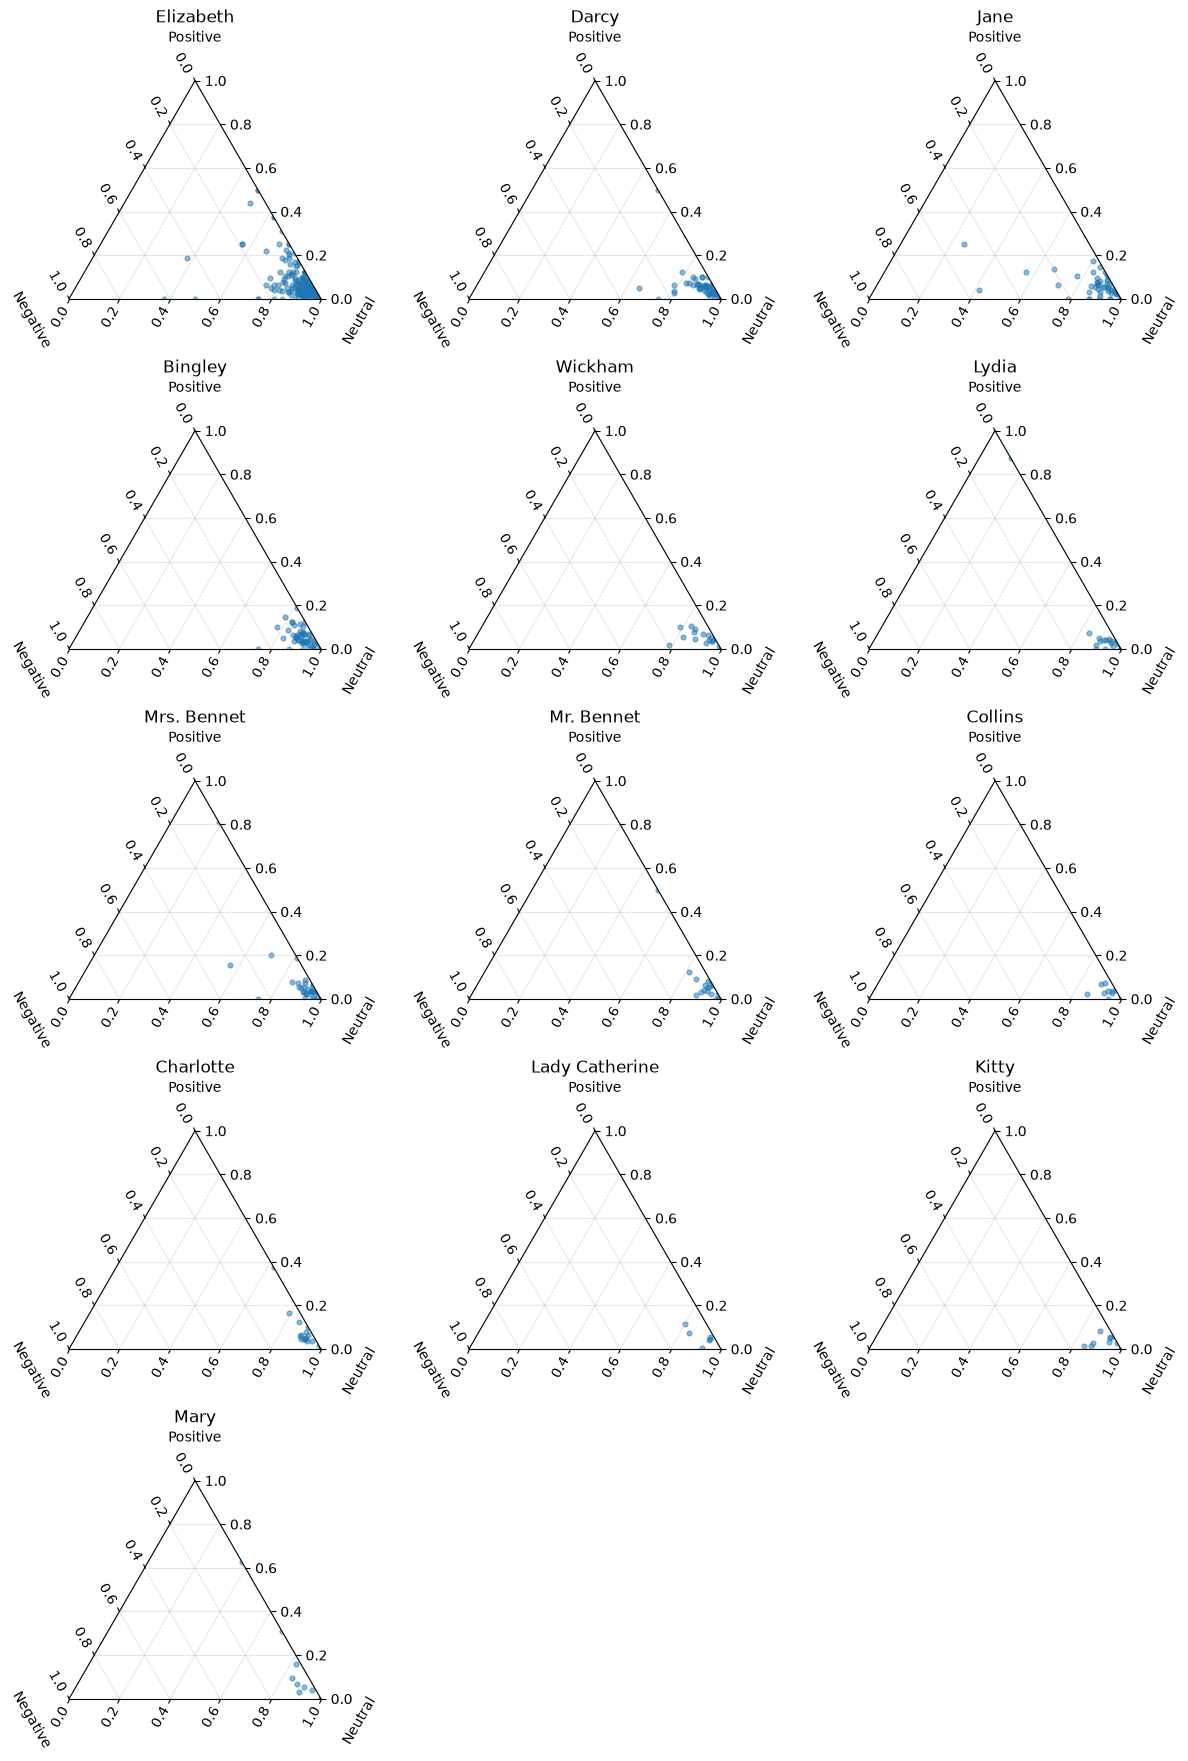

,Character,Message,Text,Positive,Negative,Neutral
0,Elizabeth,1,absolute.,0.000000,0.250000,0.750000
1,Elizabeth,2,while Mrs. Bennet was stirring the fire,0.071429,0.107143,0.821429
2,Elizabeth,3,"brought his coffee-cup back_ himself,",0.000000,0.000000,1.000000
3,Elizabeth,4,taller by the breadth of my nail,0.017857,0.000000,0.982143
4,Elizabeth,5,impropriety,0.000000,0.500000,0.500000
...,...,...,...,...,...,...
585,Mary,8,"I admire the activity of your benevolence,",0.160714,0.017857,0.821429
586,Mary,9,but every impulse of feeling should be guided ...,0.052083,0.041667,0.906250
587,Mary,10,"In point of composition,",0.000000,0.000000,1.000000
588,Mary,11,his letter does not seem defective. The idea o...,0.093750,0.067708,0.838542


In [14]:
def getSentiment(text, lemmatizer):
    tokens = []
    for token in nltk.word_tokenize(text):
        for character in token:
            if character.isalnum():
                tokens.append(token)
                break

    tagged = nltk.pos_tag(tokens)
    positive, negative, neutral = 0.0, 0.0, 0.0
    pos_tags = {"J": "a", "N": "n", "R": "r", "V": "v"}

    for word, tag in tagged:
        pos = pos_tags.get(tag[0])
        if pos is None:
            neutral += 1
            continue
        lemma = lemmatizer.lemmatize(word.lower(), pos)
        synset = lesk(tokens, lemma, pos)
        if synset is not None:
            sentiment = swn.senti_synset(synset.name())
            positive += sentiment.pos_score()
            negative += sentiment.neg_score()
            neutral += sentiment.obj_score()
        else:
            neutral += 1

    if not tokens:
        return [0.0, 0.0, 1.0]
    return [positive / len(tokens), negative / len(tokens), neutral / len(tokens)]


def task10(dataframes):
    lemmatizer = WordNetLemmatizer()
    results = []
    rows = ceil(len(dataframes) / 3)
    fig = plt.figure(figsize=(12, rows * 3.5), layout="constrained")

    for i, (name, df) in enumerate(dataframes.items(), 1):
        scores = []
        for message, text in enumerate(df["text"], 1):
            positive, negative, neutral = getSentiment(text, lemmatizer)
            scores.append([positive, negative, neutral])
            results.append([name, message, text, positive, negative, neutral])

        scores = pd.DataFrame(scores, columns=["Positive", "Negative", "Neutral"])
        ax = fig.add_subplot(rows, 3, i, projection="ternary")
        ax.scatter(scores["Positive"], scores["Negative"], scores["Neutral"], s=12, alpha=0.5)
        ax.set_tlabel("Positive")
        ax.set_llabel("Negative")
        ax.set_rlabel("Neutral")
        ax.set_title(name)
        ax.grid(alpha=0.3)

    results = pd.DataFrame(results, columns=["Character", "Message", "Text", "Positive", "Negative", "Neutral"])
    print(f"Sentiment scores:\n{results.drop(columns='Text').round(3)}")
    plt.show()
    return results

task10(dataframes)
